In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

file_path = "data/online_retail_II.xlsx"

excel_file = pd.ExcelFile(file_path)

print("Available sheets:", excel_file.sheet_names)

Available sheets: ['Year 2009-2010', 'Year 2010-2011']


In [3]:
df_2009 = pd.read_excel(file_path, sheet_name="Year 2009-2010")

df_2010 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

df = pd.concat([df_2009, df_2010], ignore_index=True)

print("Dataset loaded successfully!")
print("Total rows and columns:", df.shape)

Dataset loaded successfully!
Total rows and columns: (1067371, 8)


In [4]:
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

First 5 rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [5]:
# 1. Create a copy of the original dataset
df_clean = df.copy()

# 2. Check missing values
print("MISSING VALUES")
print(df_clean.isnull().sum())

# 3. Check duplicate records
print("\nDUPLICATE ROWS:", df_clean.duplicated().sum())

# 4. Remove duplicate records
df_clean = df_clean.drop_duplicates()

# 5. Handle missing descriptions
df_clean["Description"] = df_clean["Description"].fillna("Unknown")

# 6. Remove invalid transactions
# Negative quantity generally represents returned/cancelled items.
# Zero or negative prices are excluded from sales analysis.
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
].copy()

# 7. Convert Customer ID to nullable integer
df_clean["Customer ID"] = df_clean["Customer ID"].astype("Int64")

# 8. Create a sales column
df_clean["Sales"] = df_clean["Quantity"] * df_clean["Price"]

# 9. Check final dataset
print("\nCLEANING COMPLETED!")
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Remaining missing values:")
print(df_clean.isnull().sum())

MISSING VALUES
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

DUPLICATE ROWS: 34335

CLEANING COMPLETED!
Original rows: 1067371
Cleaned rows: 1007914
Remaining missing values:
Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    228489
Country             0
Sales               0
dtype: int64


In [6]:
# Identify outliers using the IQR method

for column in ["Quantity", "Price", "Sales"]:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower) |
        (df_clean[column] > upper)
    ]

    print(f"{column} outliers: {len(outliers)}")

Quantity outliers: 53061
Price outliers: 79000
Sales outliers: 84955


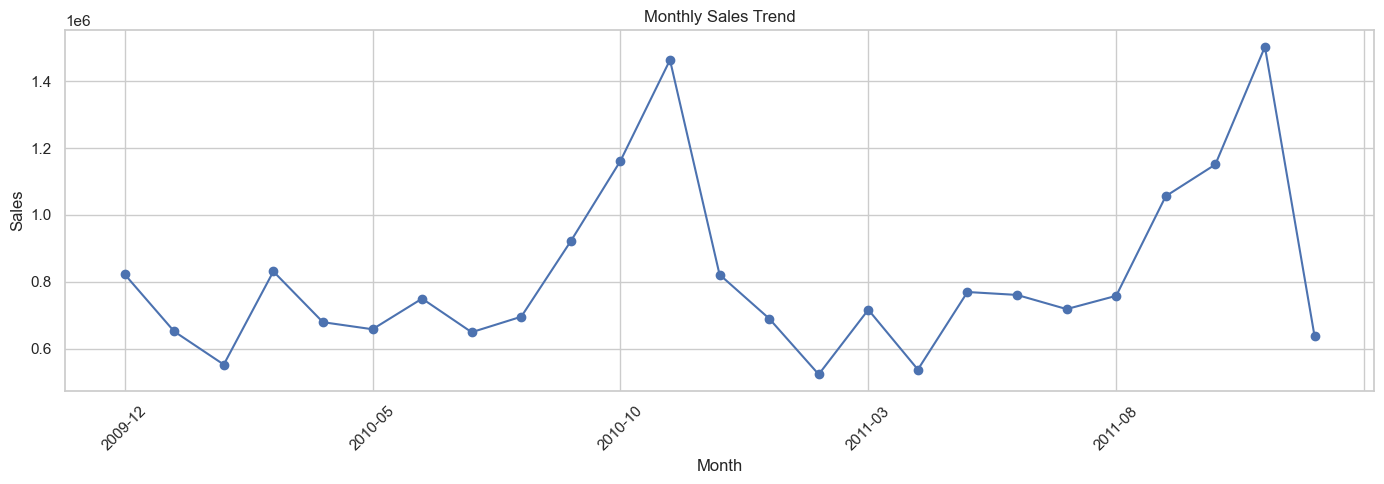

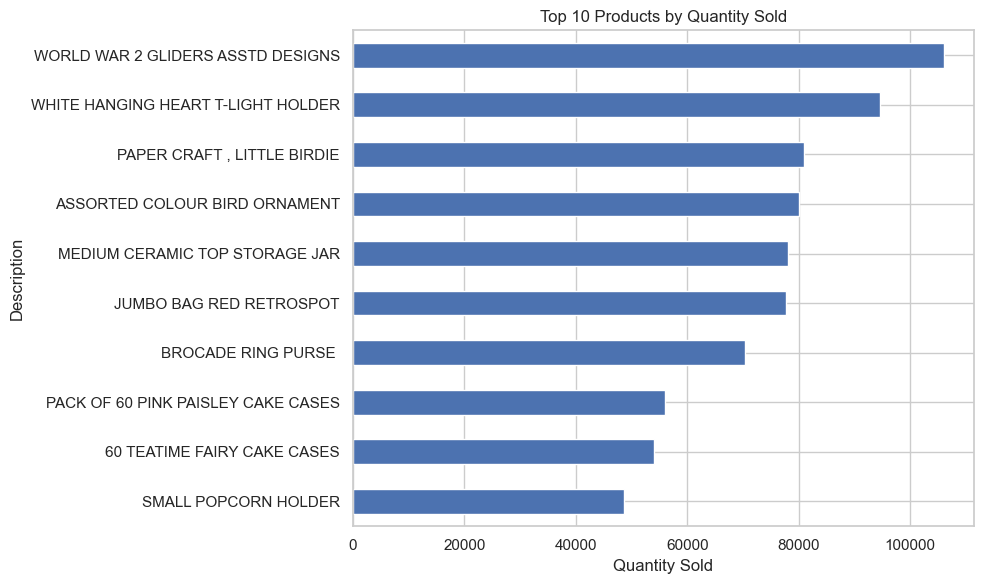

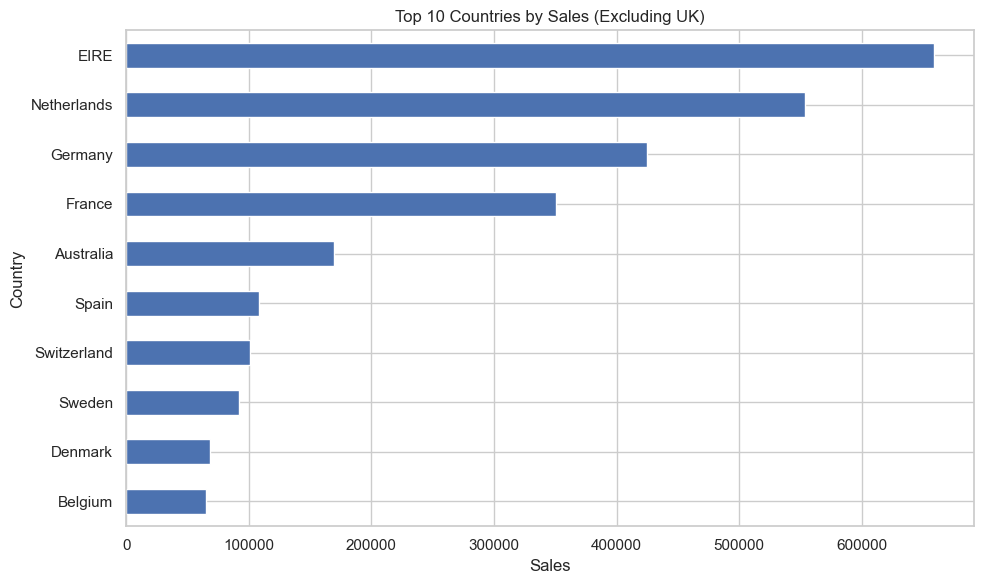

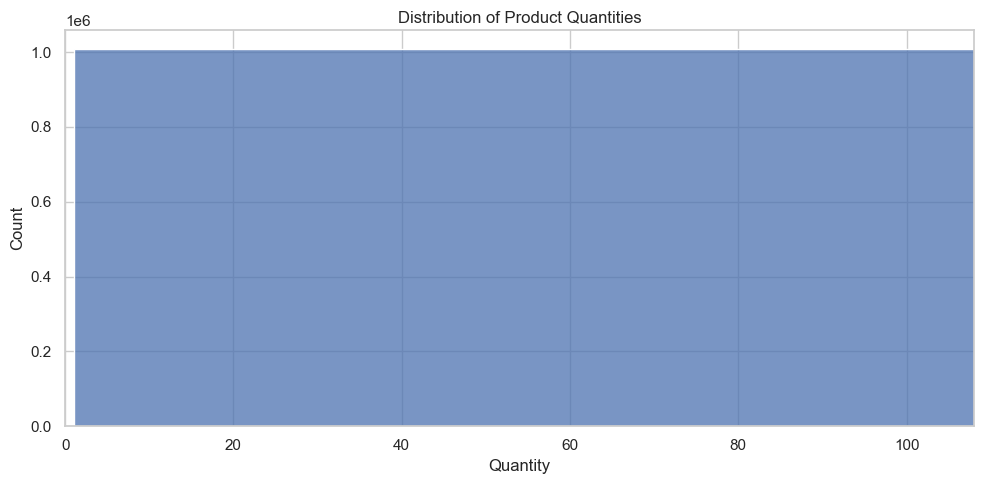

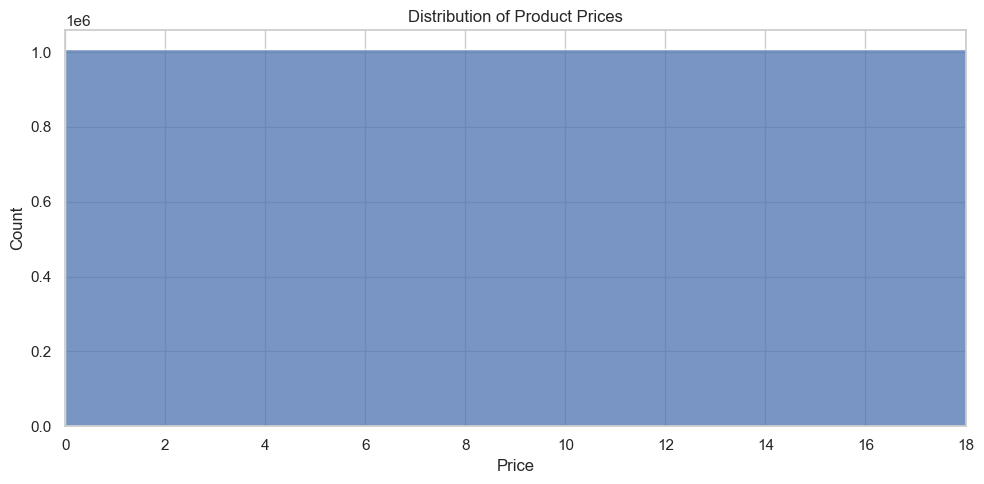

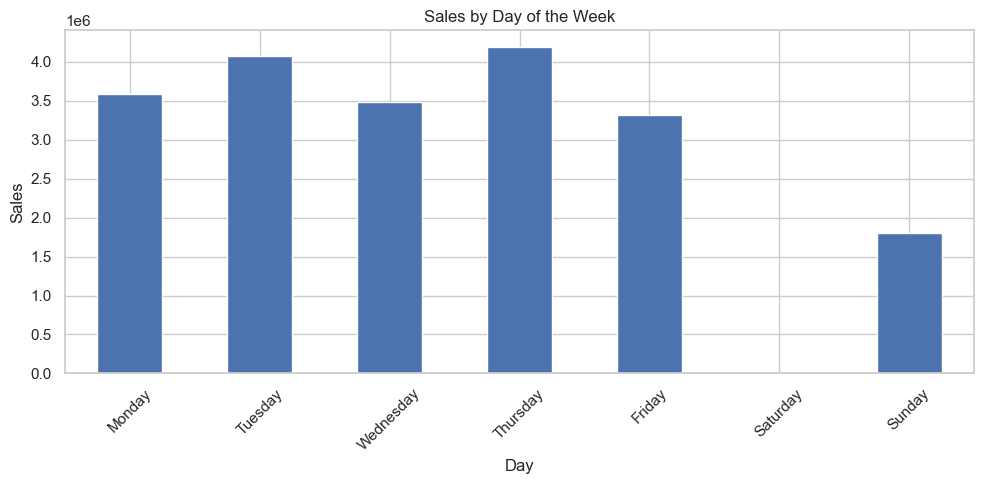

All 6 visualizations generated successfully!


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Monthly sales trend
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)

monthly_sales = df_clean.groupby("Month")["Sales"].sum()

plt.figure(figsize=(14, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 2. Top 10 selling products by quantity
top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .nlargest(10)
)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.tight_layout()
plt.show()


# 3. Top 10 countries by sales (excluding UK for comparison)
country_sales = (
    df_clean[df_clean["Country"] != "United Kingdom"]
    .groupby("Country")["Sales"]
    .sum()
    .nlargest(10)
)

plt.figure(figsize=(10, 6))
country_sales.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Sales (Excluding UK)")
plt.xlabel("Sales")
plt.tight_layout()
plt.show()


# 4. Quantity distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_clean["Quantity"], bins=50)
plt.title("Distribution of Product Quantities")
plt.xlabel("Quantity")
plt.xlim(0, df_clean["Quantity"].quantile(0.99))
plt.tight_layout()
plt.show()


# 5. Price distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_clean["Price"], bins=50)
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.xlim(0, df_clean["Price"].quantile(0.99))
plt.tight_layout()
plt.show()


# 6. Sales by day of week
df_clean["Day"] = df_clean["InvoiceDate"].dt.day_name()

day_sales = df_clean.groupby("Day")["Sales"].sum()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_sales = day_sales.reindex(day_order)

plt.figure(figsize=(10, 5))
day_sales.plot(kind="bar")
plt.title("Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("All 6 visualizations generated successfully!")

In [8]:
# BUSINESS INSIGHTS

total_sales = df_clean["Sales"].sum()
total_orders = df_clean["Invoice"].nunique()
total_products = df_clean["Description"].nunique()
total_customers = df_clean["Customer ID"].nunique()

top_product = df_clean.groupby("Description")["Quantity"].sum().idxmax()
top_country = df_clean.groupby("Country")["Sales"].sum().idxmax()
best_month = df_clean.groupby("Month")["Sales"].sum().idxmax()
best_day = df_clean.groupby("Day")["Sales"].sum().idxmax()

average_order_value = df_clean.groupby("Invoice")["Sales"].sum().mean()

print("========== BUSINESS INSIGHTS ==========")
print(f"Total sales: {total_sales:,.2f}")
print(f"Total invoices: {total_orders:,}")
print(f"Unique products: {total_products:,}")
print(f"Customers with an ID: {total_customers:,}")
print(f"Top-selling product: {top_product}")
print(f"Country with highest sales: {top_country}")
print(f"Best sales month: {best_month}")
print(f"Best sales day: {best_day}")
print(f"Average invoice value: {average_order_value:,.2f}")

========== BUSINESS INSIGHTS ==========
Total sales: 20,476,634.02
Total invoices: 40,078
Unique products: 5,399
Customers with an ID: 5,878
Top-selling product: WORLD WAR 2 GLIDERS ASSTD DESIGNS
Country with highest sales: United Kingdom
Best sales month: 2011-11
Best sales day: Thursday
Average invoice value: 510.92


In [9]:
import os

os.makedirs("output", exist_ok=True)

df_clean.to_csv("output/cleaned_retail_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
